# Module 5 — Notebook 04: Martin circuit ends (fibroblast subcluster + composition)

Notebook 03 placed the circuit's two ends: myeloid cluster 4 = OSM+/IL1B+ source;
fibroblast cluster 10 = OSMR/CHI3L1/IL1R1 target, with IL11/IL13RA2 diluted at
res 0.5 (same pattern as Kinchen before subclustering). This notebook:

1. Whole-data composition: cluster share by condition (Involved vs Uninvolved) —
   the GIMATS components (plasma, myeloid, T, stromal) should skew to Involved.
2. Fibroblast subclustering: is there an IL11/IL13RA2-high subcluster, and is it
   Involved-enriched (the Martin replication verdict)?
3. Myeloid readout: OSM/IL1B program in the LYZ+ compartment by condition.

Analyses of public datasets; all data credited to original authors.


In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt

base = os.path.expanduser("~/Documents/immune-endotypes/data/martin_2019")
adata = sc.read_h5ad(os.path.join(base, "adata_martin_qc.h5ad"))
print(adata.shape)
print(adata.obs["condition"].value_counts())

def frac_expr(ad, gene):
    x = ad[:, gene].X
    v = np.asarray(x.todense()).ravel() if sp.issparse(x) else np.asarray(x).ravel()
    return v > 0


(115029, 25356)
condition
Uninvolved    58097
Involved      56932
Name: count, dtype: int64


condition   Involved  Uninvolved  ratio_inv_uninv
leiden_0.5                                       
12             0.041       0.008             5.12
9              0.044       0.016             2.75
2              0.173       0.070             2.47
1              0.246       0.152             1.62
4              0.066       0.046             1.43
13             0.014       0.013             1.08
8              0.029       0.032             0.91
14             0.008       0.009             0.89
10             0.024       0.028             0.86
11             0.023       0.027             0.85
7              0.029       0.045             0.64
3              0.058       0.094             0.62
6              0.034       0.056             0.61
0              0.188       0.326             0.58
5              0.024       0.079             0.30


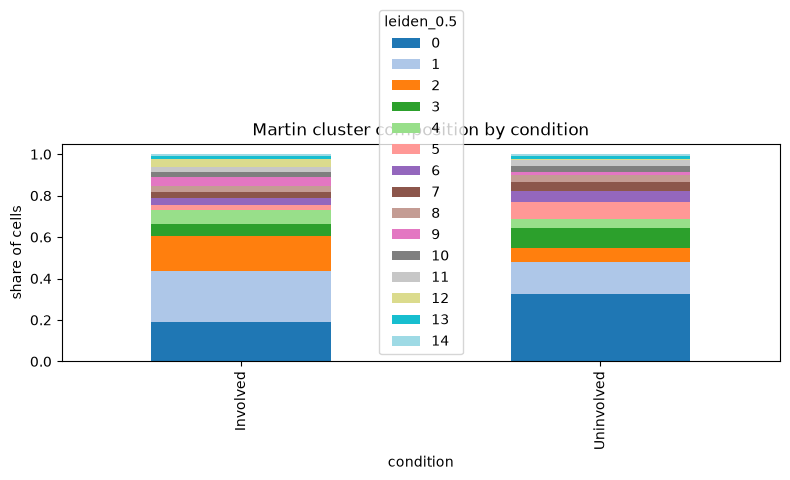

In [2]:
# 1) Whole-data composition by condition
ct = pd.crosstab(adata.obs["leiden_0.5"], adata.obs["condition"], normalize="columns").round(3)
ct["ratio_inv_uninv"] = (ct["Involved"] / ct["Uninvolved"]).round(2)
print(ct.sort_values("ratio_inv_uninv", ascending=False))
ax = ct[["Involved", "Uninvolved"]].T.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="tab20")
ax.set_ylabel("share of cells"); ax.set_title("Martin cluster composition by condition")
plt.tight_layout(); plt.savefig("../figures/martin_composition.png", dpi=130); plt.show()


fibroblast clusters: ['10']
fibroblast cells: (2942, 25356) {'Uninvolved': 1604, 'Involved': 1338}
fibroblast subclusters: 20


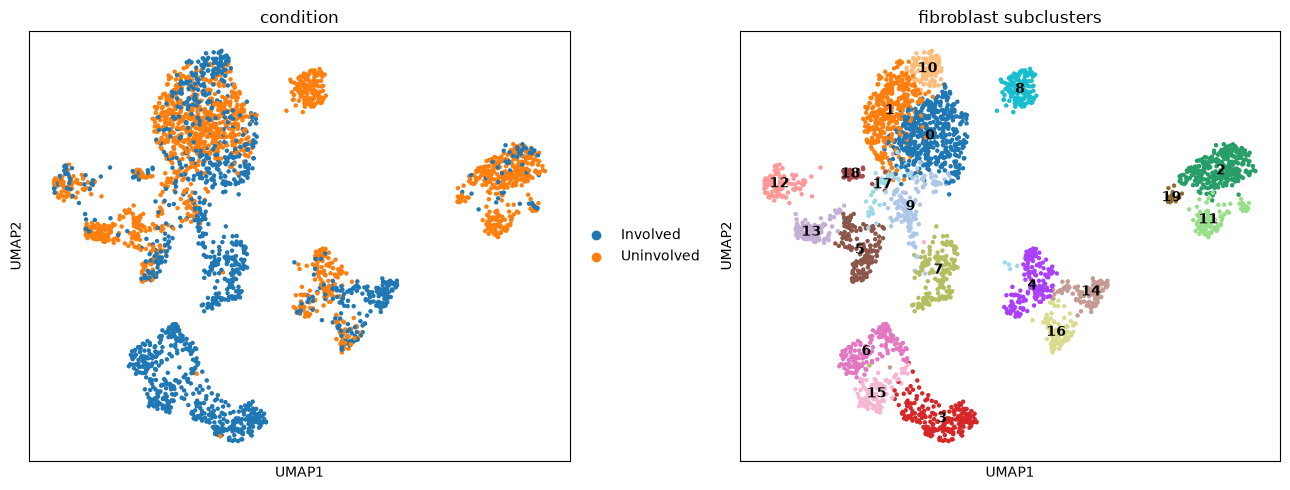

In [3]:
# 2) Fibroblast subclustering (clusters with COL1A1 fraction > 0.5)
adata.obs["_c"] = frac_expr(adata, "COL1A1")
fc = adata.obs.groupby("leiden_0.5")["_c"].mean() > 0.5
fib_clusters = list(fc[fc].index)
print("fibroblast clusters:", fib_clusters)
fib = adata[adata.obs["leiden_0.5"].isin(fib_clusters)].copy()
print("fibroblast cells:", fib.shape, dict(fib.obs["condition"].value_counts()))
sc.pp.highly_variable_genes(fib, n_top_genes=2000, batch_key="sample")
sc.tl.pca(fib, n_comps=40)
sc.pp.neighbors(fib, n_pcs=30)
sc.tl.umap(fib)
sc.tl.leiden(fib, resolution=1.0, key_added="fib_leiden")
print("fibroblast subclusters:", fib.obs["fib_leiden"].nunique())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc.pl.umap(fib, color="condition", ax=axes[0], show=False, title="condition")
sc.pl.umap(fib, color="fib_leiden", ax=axes[1], show=False, title="fibroblast subclusters", legend_loc="on data")
plt.tight_layout(); plt.savefig("../figures/martin_fibroblast_umap.png", dpi=130); plt.show()


watch present: ['IL11', 'IL13RA2', 'IL24', 'CHI3L1', 'MMP3', 'MMP10', 'IL6', 'CXCL1', 'CXCL5', 'OSMR', 'SIGIRR', 'IL1R1', 'PDPN', 'CD34', 'ADAMDEC1', 'CCL19', 'WNT2B', 'WNT5B']


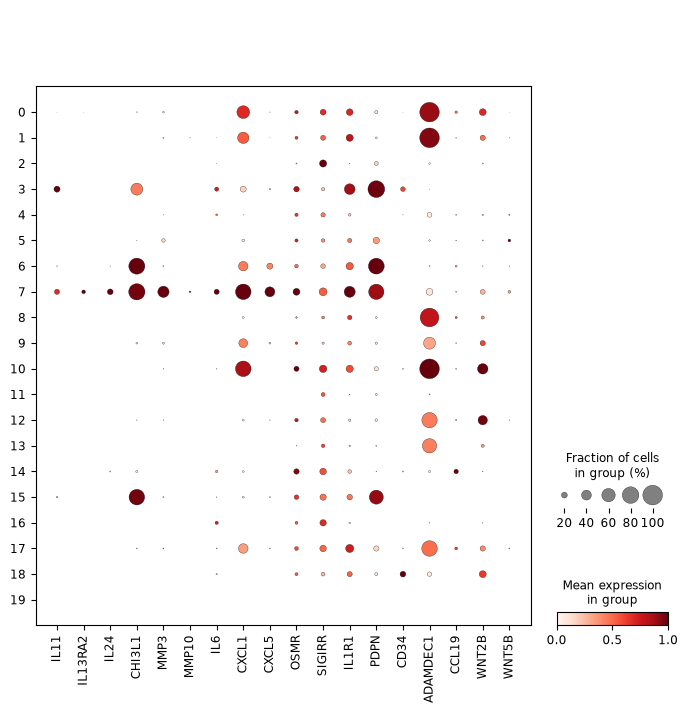

condition   Involved  Uninvolved
fib_leiden                      
0              0.109       0.205
1              0.077       0.143
2              0.026       0.148
3              0.152       0.001
4              0.025       0.080
5              0.039       0.065
6              0.114       0.000
7              0.111       0.001
8              0.000       0.087
9              0.062       0.024
10             0.049       0.022
11             0.008       0.055
12             0.025       0.041
13             0.006       0.055
14             0.070       0.001
15             0.067       0.001
16             0.035       0.026
17             0.016       0.019
18             0.007       0.016
19             0.001       0.010
condition   Involved  Uninvolved
fib_leiden                      
0              0.052       0.010
1             -0.078       0.005
2             -0.179      -0.166
3             -0.008      -0.220
4             -0.124      -0.144
5             -0.113      -0.091
6         

In [4]:
watch = ["IL11", "IL13RA2", "IL24", "CHI3L1", "MMP3", "MMP10", "IL6", "CXCL1", "CXCL5",
         "OSMR", "SIGIRR", "IL1R1", "PDPN", "CD34", "ADAMDEC1", "CCL19", "WNT2B", "WNT5B"]
watch = [g for g in watch if g in fib.var_names]
print("watch present:", watch)
sc.pl.dotplot(fib, watch, groupby="fib_leiden", standard_scale="var")
ctf = pd.crosstab(fib.obs["fib_leiden"], fib.obs["condition"], normalize="columns").round(3)
print(ctf)
prog = [g for g in ["IL11", "IL13RA2", "IL24", "CHI3L1", "MMP3", "MMP10", "IL6", "CXCL1", "CXCL5"] if g in fib.var_names]
sc.tl.score_genes(fib, prog, score_name="infl_fib_score")
print(fib.obs.groupby(["fib_leiden", "condition"])["infl_fib_score"].mean().unstack().round(3))
fib.write(os.path.join(base, "adata_martin_fibroblast.h5ad"))
print("saved adata_martin_fibroblast.h5ad")


In [5]:
# 3) Myeloid readout: LYZ-high clusters, OSM/IL1B by condition
adata.obs["_lyz"] = frac_expr(adata, "LYZ")
mc = adata.obs.groupby("leiden_0.5")["_lyz"].mean() > 0.3
mye_clusters = list(mc[mc].index)
print("myeloid clusters (LYZ fraction > 0.3):", mye_clusters)
mye = adata[adata.obs["leiden_0.5"].isin(mye_clusters)]
print("myeloid share of all cells by condition:")
print((pd.crosstab(mye.obs["condition"], columns="n")["n"] /
       adata.obs["condition"].value_counts()).round(3))
for g in ["OSM", "IL1B", "S100A8", "S100A9", "TNF"]:
    if g in mye.var_names:
        v = np.asarray(mye[:, g].X.todense()).ravel() if sp.issparse(mye.X) else np.asarray(mye[:, g].X).ravel()
        s = pd.Series(v).groupby(mye.obs["condition"].values).mean().round(3)
        print(g, dict(s))


myeloid clusters (LYZ fraction > 0.3): ['4', '6']
myeloid share of all cells by condition:
condition
Involved      0.100
Uninvolved    0.102
dtype: float64
OSM {'Involved': 0.114, 'Uninvolved': 0.042}
IL1B {'Involved': 0.83, 'Uninvolved': 0.33}
S100A8 {'Involved': 0.329, 'Uninvolved': 0.036}
S100A9 {'Involved': 0.48, 'Uninvolved': 0.08}
TNF {'Involved': 0.218, 'Uninvolved': 0.055}


## Read-out (fill in after running)

- Composition: which clusters skew to Involved (ratio > 1.5)? Do the GIMATS
  components (plasma clusters, myeloid 4, T clusters) lead the list?
- Fibroblast verdict: IL11/IL13RA2-high subcluster present? Involved-enriched?
- Myeloid: OSM/IL1B means higher in Involved, and is the myeloid compartment
  itself expanded in Involved tissue?
- Next: notebook 05 — LIANA on Martin by condition (full-circuit replication);
  notebook 06 — human integration; notebook 07 — Kinchen mouse arm.
